# Faster R-CNN — (baseline)

**Мета:** навчити pretrained **Faster R-CNN MobileNetV3-FPN** на VisDrone з 3-fold sequence-based Cross-Validation.

- `train_step=5`: кожен 5-й кадр у кожній відеопослідовності для навчання;
- `val_step=2`: кожен 2-й кадр у кожній OOF validation sequence;
- оцінюємо `mAP@[.50:.95]`, `AP50`, `AP_small`, inference ms/img;
- останній checkpoint кожного fold зберігається, а готові fold metrics і OOF predictions — у `OUTPUT_ROOT`; у **новій Kaggle-сесії** для resume треба повторно додати output попереднього запуску як Input (`RESUME_FROM_INPUT`).

**Обмеження:** `ignored_boxes` у вихідному preprocessing не використовувалися як спеціальна маска для loss. Для COCO evaluation ми наближено маркуємо їх як class-agnostic crowd;



## 0. Config, paths та залежності

In [ ]:
# Run this first. Use Kaggle Settings -> Accelerator -> GPU.
import sys, subprocess, importlib.util
if importlib.util.find_spec('pycocotools') is None:
    subprocess.check_call([sys.executable,'-m','pip','install','-q','pycocotools'])
import os, random, json, numpy as np, torch
from pathlib import Path

SEED=42
FOLDS=[0,1,2]
TRAIN_STEP=5
VAL_STEP=2
BATCH_SIZE=2
EVAL_BATCH_SIZE=2
EPOCHS=6
LR=0.002
IMG_MIN_SIZE=800
IMG_MAX_SIZE=1333
NUM_WORKERS=2
USE_AMP=True
PRETRAINED_COCO_WEIGHTS=None
RUN_NAME='f_rcnn_baseline'
OUTPUT_ROOT=Path('/kaggle/working/fasterrcnn_cv')

# Optional overrides if auto-detection picks the wrong input.
DATA_ROOT_OVERRIDE=None
PREP_ROOT_OVERRIDE=None

COMPETITION_SLUG='multiple-object-video-detection-hw-2-ucu-ai-2026'
def find_data_root():
    if DATA_ROOT_OVERRIDE: return Path(DATA_ROOT_OVERRIDE)
    opts=[Path('/kaggle/input/competitions')/COMPETITION_SLUG,
          Path('/kaggle/input')/COMPETITION_SLUG]
    for p in opts:
        if (p/'train'/'annotations_coco.json').is_file() and (p/'val'/'annotations_coco.json').is_file():
            return p
    for f in Path('/kaggle/input').rglob('annotations_coco.json'):
        p=f.parent.parent
        if (p/'train'/'annotations_coco.json').is_file() and (p/'val'/'annotations_coco.json').is_file():
            return p
    raise FileNotFoundError('Original competition images missing. Add Kaggle competition data as input.')

def find_preprocessing():
    if PREP_ROOT_OVERRIDE: return Path(PREP_ROOT_OVERRIDE)
    for f in Path('/kaggle/input').rglob('folds.json'):
        p=f.parent
        if (p/'train.json').is_file() and (p/'val.json').is_file():
            return p
    raise FileNotFoundError('Add output of 02-newpreprocessing.ipynb as a Kaggle input.')

DATA_ROOT=find_data_root()
PREP_ROOT=find_preprocessing()
print('Image dataset:',DATA_ROOT)
print('Preprocessed JSON:',PREP_ROOT)
print('Results:',OUTPUT_ROOT)
RESUME_FROM_INPUT=None
if RESUME_FROM_INPUT:
    import shutil
    shutil.copytree(RESUME_FROM_INPUT,OUTPUT_ROOT,dirs_exist_ok=True)
    print('Restored previous checkpoints from',RESUME_FROM_INPUT)

Image dataset: /kaggle/input/competitions/multiple-object-video-detection-hw-2-ucu-ai-2026
Preprocessed JSON: /kaggle/input/datasets/olenadovbenchuk/preprocessing
Results: /kaggle/working/fasterrcnn_cv


## 1. Dataset і sequence-based subsampling
Читаємо `train.json`, `val.json`, `folds.json` із preprocessing output. Folds призначені **до відбору кадрів**, щоб уникнути leakage.

In [59]:
from collections import defaultdict
from pathlib import Path
from PIL import Image
import numpy as np, torch, random, json
from torch.utils.data import Dataset, DataLoader

CLASS_NAMES = {1:'person', 2:'bicycle', 3:'car', 4:'van', 5:'truck', 6:'tricycle', 7:'bus', 8:'motor'}
NUM_CLASSES = len(CLASS_NAMES) + 1  # background ID 0

def name_of_sequence(rec):
    return Path(str(rec['file_name']).replace('\\', '/')).parent.name

def load_preprocessed(prep_root):
    data = {}
    for part in ('train','val'):
        with (prep_root / f'{part}.json').open(encoding='utf8') as f:
            data[part] = json.load(f)
    with (prep_root/'folds.json').open(encoding='utf8') as f:
        folds = json.load(f)
    # The preprocessing notebook saved all 24,201 train frames, not a sampled split.
    assert len(data['train']) == len(folds), 'folds.json needs to cover ALL train frames. Re-run preprocessing with FRAME_STEP=1.'
    assert set(folds.values()) == {0,1,2}, f'Unexpected folds: {set(folds.values())}'
    for rec in data['train']:
        assert rec['file_name'] in folds, f"Missing fold for {rec['file_name']}"
        assert set(rec) >= {'image_id','file_name','boxes','labels','ignored_boxes'}
    for rec in data['val']:
        assert set(rec) >= {'image_id','file_name','boxes','labels','ignored_boxes'}
    return data, folds

def sample_by_sequence(records, step):
    # Keep first, (step+1)-th, etc. IN EACH SEQUENCE, sorted by filename.
    per_seq = defaultdict(list)
    for rec in records:
        per_seq[name_of_sequence(rec)].append(rec)
    selected = []
    for seq in sorted(per_seq):
        selected.extend(sorted(per_seq[seq],key=lambda r:r['file_name'])[::step])
    return selected

class PreprocessedDetectionDataset(Dataset):
    def __init__(self, records, data_root, split='train', augment=False):
        self.records = records
        self.data_root = Path(data_root)
        self.split = split
        self.augment = augment
    def __len__(self):
        return len(self.records)
    def __getitem__(self, idx):
        rec = self.records[idx]
        rel = str(rec['file_name']).replace('\\','/')
        image_path = self.data_root/self.split/rel
        with Image.open(image_path) as f:
            arr = np.asarray(f.convert('RGB')).copy()
        h,w = arr.shape[:2]
        boxes = torch.as_tensor(rec['boxes'], dtype=torch.float32).reshape(-1,4).clone()
        labels = torch.as_tensor(rec['labels'], dtype=torch.int64)
        ignored = torch.as_tensor(rec['ignored_boxes'], dtype=torch.float32).reshape(-1,4).clone()
        image = torch.from_numpy(arr).permute(2,0,1).contiguous().float()/255.
        # Equivalent to preprocessing RandomHorizontalFlip(p=0.5), including both box types.
        if self.augment and random.random() < 0.5:
            image = torch.flip(image, dims=[2])
            for b in (boxes, ignored):
                if b.numel():
                    x1=b[:,0].clone(); x2=b[:,2].clone()
                    b[:,0]=w-x2; b[:,2]=w-x1
        assert boxes.shape[0] == labels.shape[0]
        # The original preprocessor excludes ignored boxes from targets but does not change detector loss.
        target = dict(boxes=boxes, labels=labels, image_id=torch.tensor(int(rec['image_id'])),
                      ignored_boxes=ignored)
        return image,target

def collate_detection(batch):
    images,targets = zip(*batch)
    return list(images),list(targets)

preprocessed, fold_map = load_preprocessed(PREP_ROOT)
train_sampled = sample_by_sequence(preprocessed['train'], TRAIN_STEP)
val_sampled = sample_by_sequence(preprocessed['train'], VAL_STEP)
assert len(train_sampled) < len(preprocessed['train']) and len(val_sampled)<len(preprocessed['train'])
print('Complete training frames:',len(preprocessed['train']))
print(f'Sampled train stride {TRAIN_STEP}:',len(train_sampled))
print(f'Sampled OOF validation stride {VAL_STEP}:',len(val_sampled))
for fold in FOLDS:
    tr=[r for r in train_sampled if int(fold_map[r['file_name']])!=fold]
    va=[r for r in val_sampled if int(fold_map[r['file_name']])==fold]
    assert tr and va, f'Empty split for fold {fold}'
    assert {name_of_sequence(r) for r in tr}.isdisjoint({name_of_sequence(r) for r in va})
    assert {r['file_name'] for r in tr}.isdisjoint({r['file_name'] for r in va})
    print(f'fold={fold}: train={len(tr)} | OOF-val={len(va)} | disjoint sequences OK')
# Note: the official 'val.json' is a separate holdout, NOT one of the three CV folds.

Complete training frames: 24201
Sampled train stride 5: 4868
Sampled OOF validation stride 2: 12114
fold=0: train=3243 | OOF-val=4044 | disjoint sequences OK
fold=1: train=3243 | OOF-val=4046 | disjoint sequences OK
fold=2: train=3250 | OOF-val=4024 | disjoint sequences OK


## 2. Faster R-CNN із pretrained weights
`num_classes=9`: 8 target classes + background. Використовуємо той самий backbone й preprocessing для baseline і tuning.

In [ ]:
import torchvision
from torchvision.models.detection import fasterrcnn_mobilenet_v3_large_fpn
from torchvision.models.detection.faster_rcnn import FastRCNNPredictor

MODEL_DEFAULTS = {
  'rpn_post_nms_top_n_train': 1000,
  'rpn_post_nms_top_n_test': 500,
  'box_positive_fraction': 0.25,
}

def make_model(settings):
    # Download pretrained COCO detection weights ONCE, cached by Torch Hub.
    model = fasterrcnn_mobilenet_v3_large_fpn(
        weights='DEFAULT' if PRETRAINED_COCO_WEIGHTS is None else None,
        weights_backbone=None if PRETRAINED_COCO_WEIGHTS else 'DEFAULT',
        trainable_backbone_layers=3,
        min_size=IMG_MIN_SIZE, max_size=IMG_MAX_SIZE,
        box_score_thresh=0.05, box_detections_per_img=300,
        box_batch_size_per_image=256,
        rpn_post_nms_top_n_train=settings['rpn_post_nms_top_n_train'],
        rpn_post_nms_top_n_test=settings['rpn_post_nms_top_n_test'],
        box_positive_fraction=settings['box_positive_fraction'],
    )
    if PRETRAINED_COCO_WEIGHTS is not None:
        weights=torch.load(PRETRAINED_COCO_WEIGHTS,map_location='cpu',weights_only=True)
        weights=weights.get('state_dict',weights)
        model.load_state_dict(weights,strict=True)  # torchvision COCO weights (91-class head)
    in_features = model.roi_heads.box_predictor.cls_score.in_features
    model.roi_heads.box_predictor = FastRCNNPredictor(in_features, NUM_CLASSES)
    return model

print('Torch:',torch.__version__,'Torchvision:',torchvision.__version__)
print('CUDA available:',torch.cuda.is_available())
assert torch.cuda.is_available(), 'Enable a GPU runtime before training (Kaggle/Colab).'
DEVICE = torch.device('cuda')
print('GPU:',torch.cuda.get_device_name(0))

Torch: 2.11.0+cu130 Torchvision: 0.26.0+cu130
CUDA available: True
GPU: Tesla T4


## 3. COCO metrics, OOF evaluation, ignored regions
COCOeval повертає standard mAP, AP50, AP_small; швидкість вимірюється тільки під час GPU forward без читання зображень. Ignored regions представлені crowd boxes для кожного класу — **це наближення**, не тотожне офіційній метриці змагання.

In [ ]:
import time, io, contextlib
from pycocotools.coco import COCO
from pycocotools.cocoeval import COCOeval


def xyxy_to_xywh(box):
    x1,y1,x2,y2 = map(float, box)
    return [x1,y1,max(0.,x2-x1),max(0.,y2-y1)]

def build_gt_dataset(images, annotations):
    return {'images':images,'annotations':annotations,
            'categories':[{'id':k,'name':v} for k,v in CLASS_NAMES.items()]}

def create_coco_gt(gt_dataset):
    coco=COCO()
    coco.dataset=gt_dataset
    with contextlib.redirect_stdout(io.StringIO()):
        coco.createIndex()
    return coco

def coco_metrics(gt_data,preds):
    coco_gt=create_coco_gt(gt_data)
    if preds:
        with contextlib.redirect_stdout(io.StringIO()):
            coco_dt=coco_gt.loadRes(preds)
    else:
        coco_dt=COCO()
        coco_dt.dataset=build_gt_dataset(gt_data['images'],[])
        with contextlib.redirect_stdout(io.StringIO()):
            coco_dt.createIndex()
    evaluator=COCOeval(coco_gt,coco_dt,'bbox')
    evaluator.params.imgIds=[x['id'] for x in gt_data['images']]
    evaluator.params.catIds=list(CLASS_NAMES)
    # Standard COCO AP uses maxDet=100 (not model's output limit=300).
    with contextlib.redirect_stdout(io.StringIO()):
        evaluator.evaluate();evaluator.accumulate();evaluator.summarize()
    return {'mAP':float(evaluator.stats[0]),
            'AP50':float(evaluator.stats[1]),
            'AP_small':float(evaluator.stats[3]),
            'AP_medium':float(evaluator.stats[4]),
            'AP_large':float(evaluator.stats[5])}

@torch.inference_mode()
def evaluate_fold(model, loader):
    model.eval()
    images_meta=[];annotations=[];preds=[];ann_id=1
    inference_seconds=0.;measured_images=0
    for batch_idx,(images,targets) in enumerate(loader):
        for image,target in zip(images,targets):
            img_id=int(target['image_id'])
            h,w=map(int,image.shape[-2:])
            images_meta.append({'id':img_id,'width':w,'height':h})
            for box,label in zip(target['boxes'].tolist(),target['labels'].tolist()):
                xywh=xyxy_to_xywh(box)
                annotations.append({'id':ann_id,'image_id':img_id,'category_id':int(label),
                                    'bbox':xywh,'area':xywh[2]*xywh[3],'iscrowd':0})
                ann_id+=1
            # Preprocessing has category-agnostic ignored regions. We represent
            # each ignored region as an ignored crowd GT for each of 8 classes,
            # so COCOeval does not penalize predictions in these regions.
            # This is an explicit APPROXIMATION; verify against competition evaluator.
            for box in target['ignored_boxes'].tolist():
                xywh=xyxy_to_xywh(box)
                for label in CLASS_NAMES:
                    annotations.append({'id':ann_id,'image_id':img_id,'category_id':int(label),
                                        'bbox':xywh,'area':xywh[2]*xywh[3],'iscrowd':1,'ignore':1})
                    ann_id+=1
        batch_cuda=[im.to(DEVICE,non_blocking=True) for im in images]
        if batch_idx>=3: torch.cuda.synchronize()
        t0=time.perf_counter()
        with torch.autocast(device_type='cuda',enabled=USE_AMP):
            outputs=model(batch_cuda)
        torch.cuda.synchronize()
        if batch_idx>=3:
            inference_seconds+=time.perf_counter()-t0
            measured_images+=len(images)
        for target,output in zip(targets,outputs):
            image_id=int(target['image_id'])
            for box,label,score in zip(output['boxes'].cpu().tolist(),
                                       output['labels'].cpu().tolist(),
                                       output['scores'].cpu().tolist()):
                if label not in CLASS_NAMES: continue
                preds.append({'image_id':image_id, 'category_id':int(label),
                              'bbox':xyxy_to_xywh(box), 'score':float(score)})
    gt_data=build_gt_dataset(images_meta,annotations)
    stats=coco_metrics(gt_data,preds)
    ms_img=1000*inference_seconds/max(measured_images,1)
    stats.update({'ms_per_image':float(ms_img),'fps':float(1000/ms_img) if ms_img>0 else None,
                  'images':len(images_meta),'predictions':len(preds)})
    return stats,gt_data,preds

## 4. Training, checkpoint resume та обʼєднання OOF
Новий pretrained model для кожного fold. Перерваний fold відновлюється з `last.pt`; завершені fold results повторно не тренуються. Повна оцінка — після останньої епохи кожного fold.

In [62]:
import os, random, hashlib, gc
from tqdm.auto import tqdm
import pandas as pd

def seed_everything(seed):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)

def train_one_epoch(model, loader, optimizer, scaler):
    model.train()
    total=0.; count=0
    bar=tqdm(loader,desc='training',leave=False)
    for images,targets in bar:
        images=[im.to(DEVICE,non_blocking=True) for im in images]
        model_targets=[{'boxes':t['boxes'].to(DEVICE), 'labels':t['labels'].to(DEVICE)}
                       for t in targets]
        optimizer.zero_grad(set_to_none=True)
        with torch.autocast(device_type='cuda',enabled=USE_AMP):
            loss_dict=model(images,model_targets)
            loss=sum(loss_dict.values())
        if not torch.isfinite(loss):
            raise RuntimeError(f'Non-finite loss: {loss_dict}')
        scaler.scale(loss).backward()
        scaler.unscale_(optimizer)
        torch.nn.utils.clip_grad_norm_(model.parameters(),10.)
        scaler.step(optimizer);scaler.update()
        count+=1;total+=loss.item();bar.set_postfix(loss=f'{loss.item():.3f}')
    return total/max(count,1)

def save_checkpoint(path,model,optimizer,scheduler,scaler,epoch,fingerprint):
    path.parent.mkdir(parents=True,exist_ok=True)
    tmp=path.with_suffix('.tmp')
    torch.save({'epoch':epoch, 'fingerprint':fingerprint, 'model':model.state_dict(),
                'optimizer':optimizer.state_dict(),'scheduler':scheduler.state_dict(),
                'scaler':scaler.state_dict()},tmp)
    tmp.replace(path)

def load_checkpoint(path,model,optimizer,scheduler,scaler,fingerprint):
    ckpt=torch.load(path,map_location='cpu',weights_only=False) # OUR OWN checkpoint only
    assert ckpt['fingerprint']==fingerprint, 'Config/split changed: refuse unsafe resume.'
    model.load_state_dict(ckpt['model'])
    optimizer.load_state_dict(ckpt['optimizer'])
    scheduler.load_state_dict(ckpt['scheduler'])
    scaler.load_state_dict(ckpt['scaler'])
    return int(ckpt['epoch'])+1

def make_loaders(fold):
    train_records=[r for r in train_sampled if int(fold_map[r['file_name']])!=fold]
    valid_records=[r for r in val_sampled if int(fold_map[r['file_name']])==fold]
    assert {name_of_sequence(r) for r in train_records}.isdisjoint(
        {name_of_sequence(r) for r in valid_records})
    train_ds=PreprocessedDetectionDataset(train_records,DATA_ROOT,'train',augment=True)
    val_ds=PreprocessedDetectionDataset(valid_records,DATA_ROOT,'train',augment=False)
    train_loader=DataLoader(train_ds,batch_size=BATCH_SIZE,shuffle=True,
                            num_workers=NUM_WORKERS,pin_memory=True,collate_fn=collate_detection,
                            persistent_workers=(NUM_WORKERS>0))
    val_loader=DataLoader(val_ds,batch_size=EVAL_BATCH_SIZE,shuffle=False,
                          num_workers=NUM_WORKERS,pin_memory=True,collate_fn=collate_detection,
                          persistent_workers=(NUM_WORKERS>0))
    return train_loader,val_loader,train_records,valid_records

def run_one_experiment(run_name,settings):
    run_dir=OUTPUT_ROOT/run_name
    run_dir.mkdir(parents=True,exist_ok=True)
    exp_config={'run_name':run_name,'settings':settings,'folds':FOLDS,
                'train_step':TRAIN_STEP,'val_step':VAL_STEP,'epochs':EPOCHS,
                'batch':BATCH_SIZE,'lr':LR,'min_size':IMG_MIN_SIZE,'max_size':IMG_MAX_SIZE,
                'seed':SEED,'architecture':'fasterrcnn_mobilenet_v3_large_fpn',
                'weights':'COCO_DEFAULT' if PRETRAINED_COCO_WEIGHTS is None else str(PRETRAINED_COCO_WEIGHTS), 'amp':USE_AMP,
                'evaluation':'COCO maxDets=100; class-agnostic ignored regions expanded to 8 crowd classes'}
    config_path=run_dir/'config.json'
    if config_path.exists():
        old=json.loads(config_path.read_text())
        if old!=exp_config:
            raise ValueError(f'Existing results for {run_name} used a different config. Pick a NEW run name; do not mix folds.')
    else:
        config_path.write_text(json.dumps(exp_config,indent=2))
    all_gt_images=[];all_gt_anns=[];all_preds=[];rows=[]
    for fold in FOLDS:
        seed_everything(SEED+fold)
        fold_dir=run_dir/f'fold_{fold}'
        fold_dir.mkdir(parents=True,exist_ok=True)
        result_path=fold_dir/'fold_result.json'
        if result_path.exists():
            print(f'[{run_name} fold {fold}] completed; loading cached evaluation')
            result=json.loads(result_path.read_text())
        else:
            train_loader,val_loader,tr,va=make_loaders(fold)
            unique_signature={'config':exp_config,'fold':fold,
                              'train_files':[r['file_name'] for r in tr],
                              'valid_files':[r['file_name'] for r in va]}
            fingerprint=hashlib.sha256(json.dumps(unique_signature,sort_keys=True).encode()).hexdigest()
            model=make_model(settings).to(DEVICE)   # fresh pretrained model for every fold
            optimizer=torch.optim.SGD([p for p in model.parameters() if p.requires_grad],
                                      lr=LR,momentum=0.9,weight_decay=1e-4)
            scheduler=torch.optim.lr_scheduler.CosineAnnealingLR(optimizer,T_max=EPOCHS,eta_min=LR*0.1)
            scaler=torch.amp.GradScaler('cuda',enabled=USE_AMP)
            last_ckpt=fold_dir/'last.pt'
            start_epoch=0
            if last_ckpt.exists():
                start_epoch=load_checkpoint(last_ckpt,model,optimizer,scheduler,scaler,fingerprint)
                print(f'[{run_name} fold {fold}] resume at epoch {start_epoch+1}')
            losses=[]
            for epoch in range(start_epoch,EPOCHS):
                start=time.perf_counter()
                avg_loss=train_one_epoch(model,train_loader,optimizer,scaler)
                scheduler.step()
                save_checkpoint(last_ckpt,model,optimizer,scheduler,scaler,epoch,fingerprint)
                losses.append({'epoch':epoch+1,'train_loss':avg_loss,'seconds':time.perf_counter()-start})
                print(f'[{run_name} | fold {fold} | {epoch+1}/{EPOCHS}] loss={avg_loss:.4f} | epoch_sec={losses[-1]["seconds"]:.0f}')
                pd.DataFrame(losses).to_csv(fold_dir/'recent_training_log.csv',index=False)
            # Full per-fold COCO evaluation only at the end to save GPU time.
            stats,gt,preds=evaluate_fold(model,val_loader)
            result={'fold':fold,'run_name':run_name,'metrics':stats,'ground_truth':gt,
                    'predictions':preds,'n_train':len(tr),'n_val':len(va),
                    'train_step':TRAIN_STEP,'val_step':VAL_STEP}
            tmp=result_path.with_suffix('.tmp')
            with tmp.open('w') as f:json.dump(result,f)
            tmp.replace(result_path)
            print(f'[{run_name} fold {fold}] mAP={stats["mAP"]:.4f}, AP50={stats["AP50"]:.4f}, AP_small={stats["AP_small"]:.4f}, ms/img={stats["ms_per_image"]:.1f}')
            del model,optimizer,scheduler,scaler,train_loader,val_loader
            gc.collect();torch.cuda.empty_cache()
        rows.append({'experiment':run_name,'fold':fold,'n_train':result['n_train'],
                     'n_val':result['n_val'],**result['metrics']})
        all_gt_images.extend(result['ground_truth']['images'])
        all_preds.extend(result['predictions'])
        for ann in result['ground_truth']['annotations']:
            # Regenerate unique GT annotation IDs across folds.
            ann=dict(ann);ann['id']=len(all_gt_anns)+1;all_gt_anns.append(ann)
    # Every sampled validation image must occur exactly once in OOF.
    ids=[x['id'] for x in all_gt_images]
    assert len(ids)==len(set(ids)), 'Duplicate image ID across OOF folds.'
    gt_oof=build_gt_dataset(all_gt_images,all_gt_anns)
    oof_stats=coco_metrics(gt_oof,all_preds)
    df=pd.DataFrame(rows)
    df.to_csv(run_dir/'fold_metrics.csv',index=False)
    summary={'run':run_name,'n_oof_frames':len(ids),
             'oof_metrics':oof_stats,'fold_mean_mAP':float(df['mAP'].mean()),
             'fold_std_mAP':float(df['mAP'].std(ddof=1)) if len(df)>1 else None,
             'mean_ms_per_image':float(df['ms_per_image'].mean())}
    (run_dir/'summary.json').write_text(json.dumps(summary,indent=2))
    (run_dir/'oof_predictions.json').write_text(json.dumps(all_preds))
    (run_dir/'oof_ground_truth.json').write_text(json.dumps(gt_oof))
    print('\nFINAL',run_name,': pooled OOF mAP=',round(oof_stats['mAP'],4),
          '| pooled OOF AP50=',round(oof_stats['AP50'],4),
          '| pooled OOF AP_small=',round(oof_stats['AP_small'],4))
    display(df[['experiment','fold','n_train','n_val','mAP','AP50','AP_small','ms_per_image']])
    return summary

## 5. Baseline: 3 folds

In [63]:
# Fixed baseline for all 3 folds, comparable with Colab tuning experiments.
BASELINE_SETTINGS=dict(MODEL_DEFAULTS)
print('Baseline Faster R-CNN settings:',BASELINE_SETTINGS)

Baseline Faster R-CNN settings: {'rpn_post_nms_top_n_train': 1000, 'rpn_post_nms_top_n_test': 500, 'box_positive_fraction': 0.25}


### Швидка перевірка одного batch перед Cross-Validation

In [64]:
# One train + one inference forward before hours of CV training.
RUN_SMOKE_TEST=True
if RUN_SMOKE_TEST:
    seed_everything(SEED)
    first_fold=FOLDS[0]
    train_loader,val_loader,_,_=make_loaders(first_fold)
    settings=BASELINE_SETTINGS if 'BASELINE_SETTINGS' in globals() else EXPERIMENTS[RUN_EXPERIMENTS[0]]
    smoke_model=make_model(settings).to(DEVICE)
    ims,ts=next(iter(train_loader)); ims=[x.to(DEVICE) for x in ims]
    ts=[{'boxes':t['boxes'].to(DEVICE),'labels':t['labels'].to(DEVICE)} for t in ts]
    smoke_model.train()
    with torch.autocast(device_type='cuda',enabled=USE_AMP):
        loss_parts=smoke_model(ims,ts)
    assert all(torch.isfinite(v).item() for v in loss_parts.values())
    smoke_model.eval()
    with torch.no_grad():
        with torch.autocast(device_type='cuda',enabled=USE_AMP):
            y=smoke_model([ims[0]])
    assert len(y)==1 and y[0]['boxes'].shape[1]==4
    print('SMOKE TEST OK | loss terms:',{k:round(float(v),3) for k,v in loss_parts.items()},
          '| predictions:',len(y[0]['boxes']))
    del smoke_model,train_loader,val_loader,ims,ts,y
    gc.collect();torch.cuda.empty_cache()

SMOKE TEST OK | loss terms: {'loss_classifier': 2.163, 'loss_box_reg': 0.674, 'loss_objectness': 0.177, 'loss_rpn_box_reg': 0.204} | predictions: 300


In [65]:
# Resumes from last.pt if a fold was interrupted; skips completed fold_result.json.
summary=run_one_experiment(RUN_NAME,BASELINE_SETTINGS)
print(json.dumps(summary,indent=2))

training:   0%|          | 0/1622 [00:00<?, ?it/s]

[f_rcnn_baseline | fold 0 | 1/6] loss=1.1825 | epoch_sec=185


training:   0%|          | 0/1622 [00:00<?, ?it/s]

[f_rcnn_baseline | fold 0 | 2/6] loss=1.0112 | epoch_sec=181


training:   0%|          | 0/1622 [00:00<?, ?it/s]

[f_rcnn_baseline | fold 0 | 3/6] loss=0.9453 | epoch_sec=181


... (28 outputs left out)

training:   0%|          | 0/1625 [00:00<?, ?it/s]

[f_rcnn_baseline | fold 2 | 6/6] loss=0.8241 | epoch_sec=186
[f_rcnn_baseline fold 2] mAP=0.0926, AP50=0.2040, AP_small=0.0139, ms/img=31.5

FINAL f_rcnn_baseline : pooled OOF mAP= 0.1042 | pooled OOF AP50= 0.2239 | pooled OOF AP_small= 0.0148


,experiment,fold,n_train,n_val,mAP,AP50,AP_small,ms_per_image
0,f_rcnn_baseline,0,3243,4044,0.129168,0.271905,0.024976,31.920556
1,f_rcnn_baseline,1,3243,4046,0.099284,0.213639,0.014007,29.521522
2,f_rcnn_baseline,2,3250,4024,0.092586,0.203965,0.013875,31.466755


{
  "run": "f_rcnn_baseline",
  "n_oof_frames": 12114,
  "oof_metrics": {
    "mAP": 0.10422543012240457,
    "AP50": 0.2238697979771438,
    "AP_small": 0.014837431059878987,
    "AP_medium": 0.08466004471635634,
    "AP_large": 0.2713400540647855
  },
  "fold_mean_mAP": 0.10701283105622894,
  "fold_std_mAP": 0.01947713261175272,
  "mean_ms_per_image": 30.969611035728605
}


## 6. Failure cases

In [66]:
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle
from collections import defaultdict

def iou_xywh(a,b):
    ax1,ay1,aw,ah=a; bx1,by1,bw,bh=b
    x1=max(ax1,bx1);y1=max(ay1,by1)
    x2=min(ax1+aw,bx1+bw);y2=min(ay1+ah,by1+bh)
    inter=max(0.,x2-x1)*max(0.,y2-y1)
    return inter/(aw*ah+bw*bh-inter+1e-8)

def plot_failure_cases(run_name, num_cases=3, score_thresh=0.4):
    folder=OUTPUT_ROOT/run_name
    gt=json.loads((folder/'oof_ground_truth.json').read_text())
    pred=json.loads((folder/'oof_predictions.json').read_text())
    by_gt=defaultdict(list);by_pred=defaultdict(list);by_ignored=defaultdict(list)
    for a in gt['annotations']:
        (by_ignored if a['iscrowd'] else by_gt)[a['image_id']].append(a)
    for p in pred:
        if p['score']>=score_thresh:by_pred[p['image_id']].append(p)
    scored=[]
    for image in gt['images']:
        k=image['id'];g=by_gt[k];p=by_pred[k]
        # Simple failure screening (not an official TIDE error breakdown).
        missed=sum(not any(q['category_id']==a['category_id'] and
                          iou_xywh(a['bbox'],q['bbox'])>=0.5 for q in p) for a in g)
        false_pos=sum(not any(q['category_id']==a['category_id'] and
                             iou_xywh(a['bbox'],q['bbox'])>=0.5 for a in g) for q in p)
        scored.append((missed+0.5*false_pos,k,missed,false_pos))
    best=sorted(scored,reverse=True)[:num_cases]
    # Map IDs using saved preprocessed records, no filename metadata loss.
    id_to_rec={r['image_id']:r for r in preprocessed['train']}
    fig,axes=plt.subplots(len(best),2,figsize=(14,4.4*len(best)),squeeze=False)
    for row,(_,k,missed,fp) in enumerate(best):
        rec=id_to_rec[k]
        rel=str(rec['file_name']).replace('\\','/')
        with Image.open(DATA_ROOT/'train'/rel) as f: image=np.asarray(f.convert('RGB'))
        for col in range(2):axes[row,col].imshow(image);axes[row,col].axis('off')
        axes[row,0].set_title(f'GT: {name_of_sequence(rec)} | id={k} | missed={missed}')
        axes[row,1].set_title(f'Predictions ≥{score_thresh} | possible FP={fp}')
        for a in by_gt[k]:
            x,y,w,h=a['bbox']
            axes[row,0].add_patch(Rectangle((x,y),w,h,fill=False,edgecolor='lime',linewidth=0.7))
        # Annotation file describes ignored rectangles as no-class regions.
        for box in rec['ignored_boxes']:
            x1,y1,x2,y2=box
            axes[row,0].add_patch(Rectangle((x1,y1),x2-x1,y2-y1,fill=False,
                                            edgecolor='orange',linestyle='--',linewidth=0.8))
        for q in by_pred[k]:
            x,y,w,h=q['bbox']
            axes[row,1].add_patch(Rectangle((x,y),w,h,fill=False,edgecolor='red',linewidth=0.7))
    plt.tight_layout()
    out=folder/'failure_cases.png'
    plt.savefig(out,dpi=160,bbox_inches='tight')
    plt.show()
    print('Saved:',out)

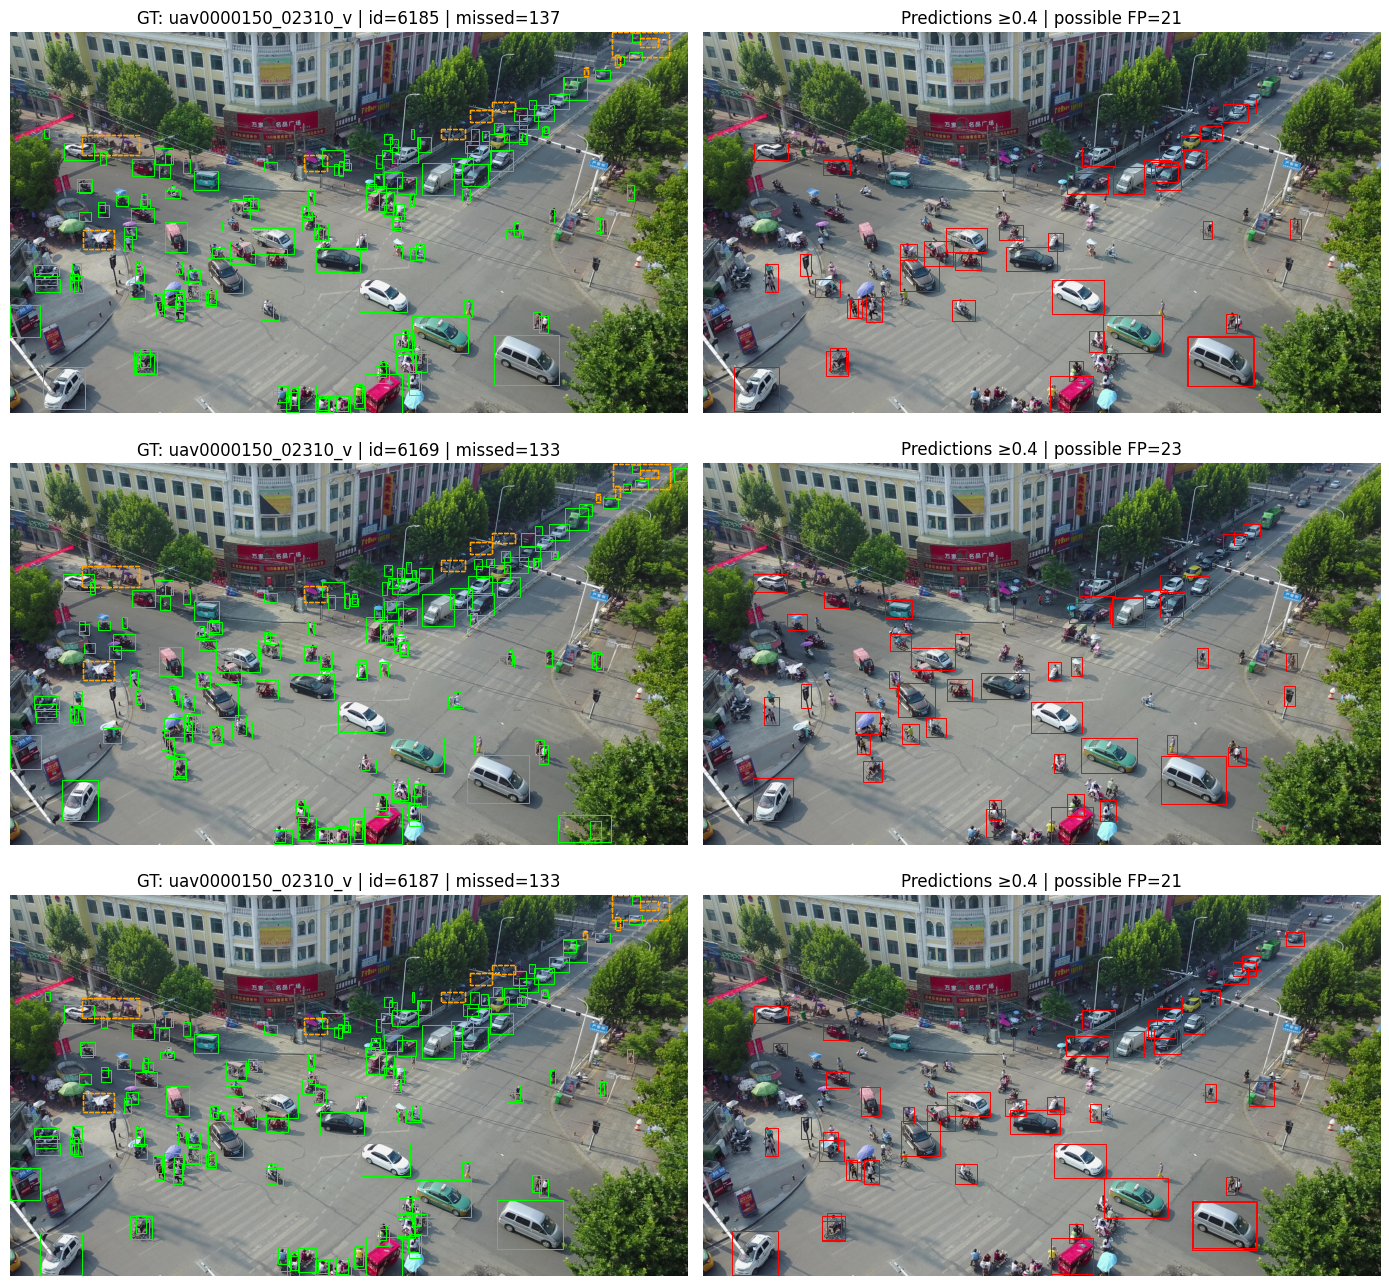

Saved: /kaggle/working/fasterrcnn_cv/f_rcnn_baseline/failure_cases.png


In [ ]:
# Select 3 images with many obvious missed / extra detections.
plot_failure_cases(RUN_NAME,num_cases=3,score_thresh=0.4)



- **RPN** пропонує candidate regions, **RoI head** класифікує та уточнює їхні box coordinates.
- `tune_rpn` змінює максимальну кількість proposals після NMS; це може покращити recall у щільних сценах, але збільшує обчислення.
- `tune_roi` змінює бажану частку positive RoI під час семплювання; **фактична** частка залежить від доступних positive proposals.
- Підсумкове `OOF mAP` обчислене на об'єднаних OOF predictions, а `fold_mean_mAP` — це середнє трьох окремих mAP; це різні величини.


#### Зберігання данних

In [69]:

from pathlib import Path

root = Path("/kaggle/working/fasterrcnn_cv/f_rcnn_baseline")

required_files = [
    root / "summary.json",
    root / "fold_metrics.csv",
    root / "oof_predictions.json",
    root / "oof_ground_truth.json",
    root / "failure_cases.png",
]

for fold in range(3):
    required_files += [
        root / f"fold_{fold}" / "last.pt",
        root / f"fold_{fold}" / "fold_result.json",
    ]

for p in required_files:
    status = "OK" if p.is_file() else "MISSING"
    print(f"{status:8} {p.name} ({p.parent.name})")

assert all(p.is_file() for p in required_files)
print("All required files are present!")


OK       summary.json (f_rcnn_baseline)
OK       fold_metrics.csv (f_rcnn_baseline)
OK       oof_predictions.json (f_rcnn_baseline)
OK       oof_ground_truth.json (f_rcnn_baseline)
OK       failure_cases.png (f_rcnn_baseline)
OK       last.pt (fold_0)
OK       fold_result.json (fold_0)
OK       last.pt (fold_1)
OK       fold_result.json (fold_1)
OK       last.pt (fold_2)
OK       fold_result.json (fold_2)
All required files are present!


In [68]:

import zipfile
from pathlib import Path
from IPython.display import FileLink, display

root = Path("/kaggle/working/fasterrcnn_cv/f_rcnn_baseline")
archive = Path("/kaggle/working/fasterrcnn_baseline_backup.zip")

with zipfile.ZipFile(
    archive, "w",
    compression=zipfile.ZIP_DEFLATED,
    compresslevel=1
) as z:
    for file in root.rglob("*"):
        if file.is_file():
            z.write(file, arcname=file.relative_to(root.parent))

print(f"Backup size: {archive.stat().st_size / 1024**2:.1f} MB")
display(FileLink(str(archive)))


Backup size: 637.7 MB


/kaggle/working/fasterrcnn_baseline_backup.zip